# SafeDrive — Notebook 2: Model Building, Validation, Tracking and Explainability

This notebook compares a class-weighted logistic regression baseline with an Optuna-tuned decision tree. It loads the Stage 1 artifact and fits imputers, scalers and encoders on training data only. The split uses `test_size=0.20`, `stratify=y`, and `random_state=42`.

## 1. Imports, paths and Stage 1 artifacts

In [48]:
from pathlib import Path
import json, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report
)

NOTEBOOK_DIR = Path.cwd()
# Check standard Capstone path first; fallback to current directory for Colab/local testing
PROJECT_DIR = Path("/mnt/data/SafeDrive_Capstone") if Path("/mnt/data/SafeDrive_Capstone").exists() else NOTEBOOK_DIR
STAGE1_DIR = PROJECT_DIR / "outputs" / "stage1" if (PROJECT_DIR / "outputs" / "stage1").exists() else PROJECT_DIR
OUT_DIR = PROJECT_DIR / "outputs" / "stage2" if "outputs" in [p.name for p in PROJECT_DIR.iterdir()] else PROJECT_DIR
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Fallback paths to search locally if the stage1 output directory is not found
DATA_FILE = STAGE1_DIR / "cleaned_modeling_data.csv" if (STAGE1_DIR / "cleaned_modeling_data.csv").exists() else PROJECT_DIR / "cleaned_modeling_data.csv"
MANIFEST_FILE = STAGE1_DIR / "stage1_feature_manifest.json" if (STAGE1_DIR / "stage1_feature_manifest.json").exists() else PROJECT_DIR / "stage1_feature_manifest.json"

# If still not found, search the current directory for any files with these names
if not DATA_FILE.exists():
    found_data = list(Path.cwd().glob("**/cleaned_modeling_data.csv"))
    if found_data:
        DATA_FILE = found_data[0]
if not MANIFEST_FILE.exists():
    found_manifest = list(Path.cwd().glob("**/stage1_feature_manifest.json"))
    if found_manifest:
        MANIFEST_FILE = found_manifest[0]

if not DATA_FILE.exists() or not MANIFEST_FILE.exists():
    raise FileNotFoundError(
        f"Could not find Stage 1 artifacts.\n"
        f"Expected DATA_FILE: {DATA_FILE}\n"
        f"Expected MANIFEST_FILE: {MANIFEST_FILE}\n"
        f"Please upload these files to your environment or run Notebook 1 first."
    )

df = pd.read_csv(DATA_FILE)
manifest = json.loads(MANIFEST_FILE.read_text())
features = manifest["final_modeling_features"]
target = "is_claim"
print("Data shape:", df.shape, "| feature count:", len(features))

Data shape: (58592, 54) | feature count: 30


## 2. Split and preprocessing
The full pipeline keeps preprocessing inside cross-validation. The fitted preprocessor is learned from the training fold only, so the test data cannot influence imputation, scaling or category discovery.

In [49]:
# Drop rows where target variable is missing to prevent stratification errors
df_clean = df.dropna(subset=[target]).copy()

X = df_clean[features].copy()
y = df_clean[target].astype(int).copy()
policy_ids = df_clean["policy_id"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
train_indices = X_train.index.copy()
test_indices = X_test.index.copy()
print("Train shape:", X_train.shape, "claim rate:", round(y_train.mean(), 4))
print("Test shape:", X_test.shape, "claim rate:", round(y_test.mean(), 4))

Train shape: (46873, 30) claim rate: 0.064
Test shape: (11719, 30) claim rate: 0.064


In [50]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 22
Categorical features: 8


## 3. Logistic regression assumptions
Policy IDs are expected to identify policies, but repeated IDs are checked rather than assumed absent. The dataset does not include a verified customer/person identifier, so true independence between policyholders cannot be fully established. Decile-binned empirical log-odds plots provide a visual diagnostic, not a definitive statistical proof.

In [51]:
print("Repeated policy IDs in the cleaned data:", int(df["policy_id"].duplicated().sum()))
print("Unique policy IDs:", int(df["policy_id"].nunique()))
print("Independence limitation: policy_id is a policy identifier, not a verified person-level identifier.")

Repeated policy IDs in the cleaned data: 0
Unique policy IDs: 58592
Independence limitation: policy_id is a policy identifier, not a verified person-level identifier.


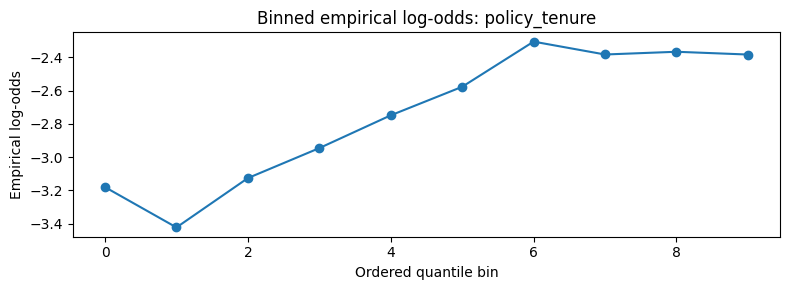

,bin,mean,count,empirical_log_odds
0,"(0.0017399999999999998, 0.0819]",0.039889,4688,-3.180946
1,"(0.0819, 0.139]",0.031577,4687,-3.423250
2,"(0.139, 0.272]",0.042031,4687,-3.126404
3,"(0.272, 0.426]",0.049925,4687,-2.946012
4,"(0.426, 0.575]",0.060154,4688,-2.748815
5,"(0.575, 0.777]",0.070621,4687,-2.577191
6,"(0.777, 1.005]",0.090676,4687,-2.305405
7,"(1.005, 1.078]",0.084489,4687,-2.382861
8,"(1.078, 1.161]",0.085769,4687,-2.366424
9,"(1.161, 1.397]",0.084471,4688,-2.383094


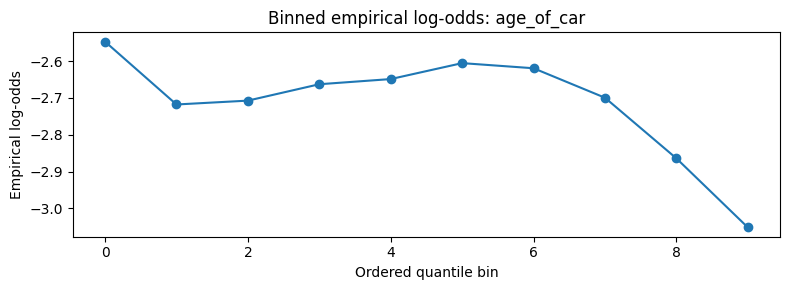

,bin,mean,count,empirical_log_odds
0,"(-0.001, 0.01]",0.072647,9264,-2.546725
1,"(0.01, 0.02]",0.061940,4133,-2.717639
2,"(0.02, 0.03]",0.062553,3565,-2.707153
3,"(0.03, 0.04]",0.065217,3036,-2.662588
4,"(0.04, 0.06]",0.066080,5115,-2.648522
5,"(0.06, 0.08]",0.068805,4520,-2.605187
6,"(0.08, 0.1]",0.067917,4638,-2.619132
7,"(0.1, 0.12]",0.063012,3904,-2.699340
8,"(0.12, 0.15]",0.053949,5153,-2.864254
9,"(0.15, 0.245]",0.045134,3545,-3.051935


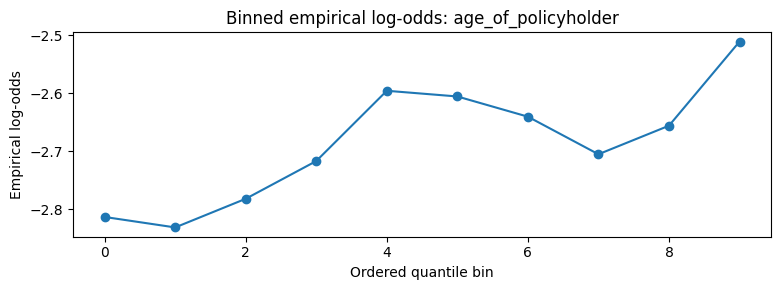

,bin,mean,count,empirical_log_odds
0,"(0.287, 0.317]",0.056623,4839,-2.813046
1,"(0.317, 0.356]",0.055668,5443,-2.831076
2,"(0.356, 0.385]",0.058321,4098,-2.781700
3,"(0.385, 0.423]",0.061998,5355,-2.716648
4,"(0.423, 0.452]",0.069427,4033,-2.595521
5,"(0.452, 0.49]",0.068796,5291,-2.605332
6,"(0.49, 0.529]",0.066597,4775,-2.640180
7,"(0.529, 0.567]",0.062683,3749,-2.704925
8,"(0.567, 0.644]",0.065636,4723,-2.655738
9,"(0.644, 0.822]",0.075104,4567,-2.510807


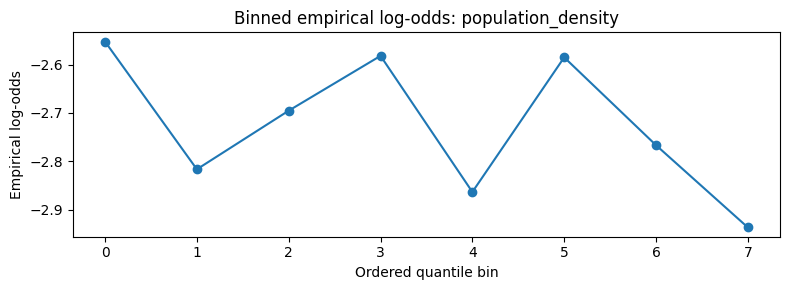

,bin,mean,count,empirical_log_odds
0,"(289.999, 4076.0]",0.072245,5772,-2.552700
1,"(4076.0, 5410.0]",0.056450,3915,-2.816302
2,"(5410.0, 7788.0]",0.063253,5644,-2.695270
3,"(7788.0, 8794.0]",0.070300,10953,-2.582084
4,"(8794.0, 17804.0]",0.054006,3370,-2.863142
5,"(17804.0, 27003.0]",0.070097,6491,-2.585199
6,"(27003.0, 34738.0]",0.059158,6322,-2.766555
7,"(34738.0, 58339.5]",0.050386,4406,-2.936346


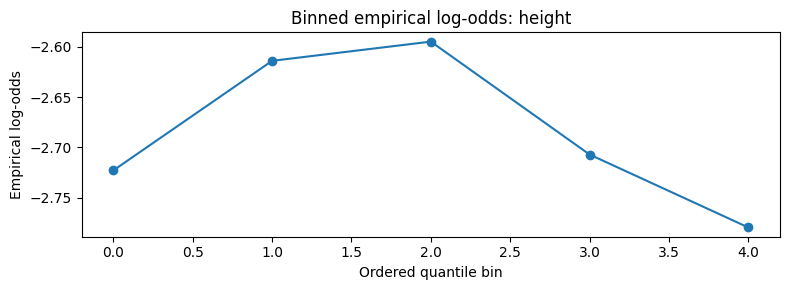

,bin,mean,count,empirical_log_odds
0,"(1474.999, 1500.0]",0.061641,16158,-2.722800
1,"(1500.0, 1523.0]",0.068247,3839,-2.613935
2,"(1523.0, 1530.0]",0.069471,11055,-2.594847
3,"(1530.0, 1635.0]",0.062560,11509,-2.707031
4,"(1635.0, 1825.0]",0.058442,4312,-2.779509


In [52]:
continuous_features = [c for c in numeric_features if X_train[c].nunique(dropna=True) > 10]
for column in continuous_features[:8]:
    temp = pd.DataFrame({"x": X_train[column], "y": y_train}).dropna()
    temp["bin"] = pd.qcut(temp["x"], q=10, duplicates="drop")
    summary = temp.groupby("bin", observed=False)["y"].agg(["mean", "count"]).reset_index()
    # Clip rates to avoid log(0) or log(1).
    safe_rate = summary["mean"].clip(1e-4, 1 - 1e-4)
    summary["empirical_log_odds"] = np.log(safe_rate / (1 - safe_rate))
    plt.figure(figsize=(8, 3))
    plt.plot(range(len(summary)), summary["empirical_log_odds"], marker="o")
    plt.title(f"Binned empirical log-odds: {column}")
    plt.xlabel("Ordered quantile bin")
    plt.ylabel("Empirical log-odds")
    plt.tight_layout()
    plt.show()
    display(summary)

### Formal Box–Tidwell-style diagnostic
For each continuous predictor, this diagnostic tests whether an added \(x\log(x)\) term is associated with the outcome in a univariate logistic model. Values are shifted to be positive before taking the logarithm. It is a screening diagnostic, not a substitute for a correctly specified multivariable model.

In [53]:
import statsmodels.api as sm

box_tidwell_rows = []
for column in continuous_features:
    values = X_train[column].astype(float)
    shift = 1 - values.min() if values.min() <= 0 else 0
    x_positive = values + shift
    x_log = x_positive * np.log(x_positive.clip(lower=1e-8))
    diagnostic_data = pd.DataFrame({
        "target": y_train,
        "x": x_positive,
        "x_log": x_log
    }).replace([np.inf, -np.inf], np.nan).dropna()
    try:
        diagnostic_model = sm.GLM(
            diagnostic_data["target"],
            sm.add_constant(diagnostic_data[["x", "x_log"]]),
            family=sm.families.Binomial()
        ).fit()
        p_value = diagnostic_model.pvalues.get("x_log", np.nan)
        box_tidwell_rows.append({
            "feature": column,
            "x_log_p_value": p_value,
            "potential_nonlinearity_at_0_05": bool(p_value < 0.05) if pd.notna(p_value) else None
        })
    except Exception as error:
        box_tidwell_rows.append({
            "feature": column, "x_log_p_value": np.nan,
            "potential_nonlinearity_at_0_05": None
        })
        print("Box-Tidwell diagnostic could not fit for", column, ":", str(error)[:120])

box_tidwell_table = pd.DataFrame(box_tidwell_rows).sort_values("x_log_p_value")
display(box_tidwell_table)
box_tidwell_table.to_csv(OUT_DIR / "box_tidwell_diagnostics.csv", index=False)

,feature,x_log_p_value,potential_nonlinearity_at_0_05
0,policy_tenure,0.000016,True
3,population_density,0.004367,True
1,age_of_car,0.245787,False
4,height,0.344517,False
2,age_of_policyholder,0.731782,False


## 4. Logistic regression baseline and evaluation

In [54]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train, y_train)
lr_probability = lr_pipeline.predict_proba(X_test)[:, 1]
lr_prediction = (lr_probability >= 0.5).astype(int)

def evaluate_predictions(y_true, predicted, probability):
    return {
        "accuracy": accuracy_score(y_true, predicted),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "f1": f1_score(y_true, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probability)
    }

lr_test_metrics = evaluate_predictions(y_test, lr_prediction, lr_probability)
display(pd.DataFrame([lr_test_metrics], index=["Logistic Regression"]).T)

,Logistic Regression
accuracy,0.569076
precision,0.080242
recall,0.548000
f1,0.139986
roc_auc,0.585229


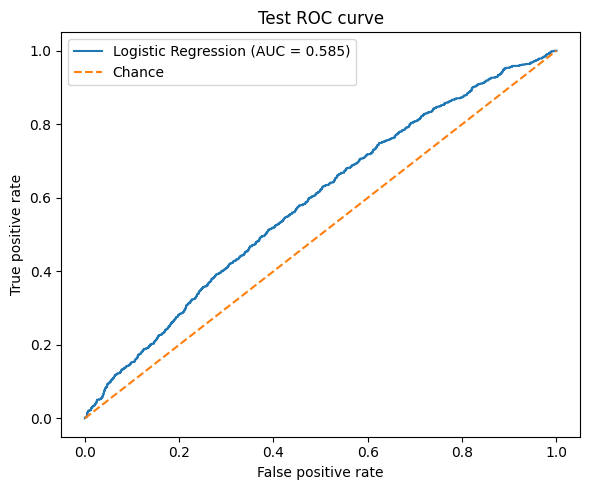

In [55]:
fpr, tpr, thresholds = roc_curve(y_test, lr_probability)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {lr_test_metrics['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Test ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

In [56]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv = cross_validate(
    lr_pipeline, X_train, y_train, cv=cv5,
    scoring={"roc_auc": "roc_auc", "f1": "f1"},
    return_train_score=False, n_jobs=-1
)
print(f"LR CV ROC-AUC: {lr_cv['test_roc_auc'].mean():.4f} ± {lr_cv['test_roc_auc'].std():.4f}")
print(f"LR CV F1:      {lr_cv['test_f1'].mean():.4f} ± {lr_cv['test_f1'].std():.4f}")

LR CV ROC-AUC: 0.6102 ± 0.0062
LR CV F1:      0.1501 ± 0.0028


In [57]:
fitted_pre = lr_pipeline.named_steps["preprocessor"]
feature_names = fitted_pre.get_feature_names_out()
coefficients = lr_pipeline.named_steps["model"].coef_[0]
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(np.clip(coefficients, -20, 20)),
    "direction": np.where(coefficients > 0, "Higher claim odds", "Lower claim odds")
})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
coefficient_table = coefficient_table.sort_values("absolute_coefficient", ascending=False)
display(coefficient_table.head(30))
coefficient_table.to_csv(OUT_DIR / "logistic_regression_coefficients.csv", index=False)

,feature,coefficient,odds_ratio,direction,absolute_coefficient
31,cat__area_cluster_C18,0.830949,2.295495,Higher claim odds,0.830949
30,cat__area_cluster_C17,-0.467366,0.626651,Lower claim odds,0.467366
35,cat__area_cluster_C21,0.402247,1.495181,Higher claim odds,0.402247
0,num__policy_tenure,0.382237,1.465560,Higher claim odds,0.382237
38,cat__area_cluster_C4,0.308839,1.361844,Higher claim odds,0.308839
41,cat__area_cluster_C7,-0.279718,0.755997,Lower claim odds,0.279718
28,cat__area_cluster_C15,-0.260383,0.770756,Lower claim odds,0.260383
29,cat__area_cluster_C16,-0.249104,0.779499,Lower claim odds,0.249104
24,cat__area_cluster_C11,-0.233635,0.791651,Lower claim odds,0.233635
37,cat__area_cluster_C3,0.201934,1.223767,Higher claim odds,0.201934


## 5. Optuna-tuned decision tree
Optuna searches the rubric-specified ranges using 25 trials, a seeded TPE sampler, and three-fold stratified ROC-AUC. The pipeline fits its own preprocessing separately inside each CV fold.

In [58]:
!pip install -q optuna

try:
  import optuna
except ImportError as error:
    raise ImportError from error

from optuna.samplers import TPESampler

def make_tree_pipeline(params):
    fresh_preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ])
    tree = DecisionTreeClassifier(
        **params, class_weight="balanced", random_state=42
    )
    return Pipeline([("preprocessor", fresh_preprocessor), ("model", tree)])

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 50),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30)
    }
    candidate = make_tree_pipeline(params)
    scores = cross_val_score(candidate, X_train, y_train, cv=cv3, scoring="roc_auc", n_jobs=-1)
    return float(scores.mean())

study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))
study.optimize(objective, n_trials=25, show_progress_bar=True)
print("Best trial ROC-AUC:", study.best_value)
print("Best hyperparameters:", study.best_params)

[I 2026-10-25 12:30:28,787] A new study created in memory with name: no-name-efd5288b-3966-468d-a802-c26b4d949cb2


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-25 12:30:30,587] Trial 0 finished with value: 0.6179051881397067 and parameters: {'max_depth': 7, 'min_samples_split': 48, 'min_samples_leaf': 22}. Best is trial 0 with value: 0.6179051881397067.
[I 2026-10-25 12:30:32,547] Trial 1 finished with value: 0.5869538413056932 and parameters: {'max_depth': 10, 'min_samples_split': 9, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.6179051881397067.
[I 2026-10-25 12:30:34,076] Trial 2 finished with value: 0.6319532761479428 and parameters: {'max_depth': 3, 'min_samples_split': 44, 'min_samples_leaf': 19}. Best is trial 2 with value: 0.6319532761479428.
[I 2026-10-25 12:30:37,386] Trial 3 finished with value: 0.5836664769042548 and parameters: {'max_depth': 12, 'min_samples_split': 3, 'min_samples_leaf': 30}. Best is trial 2 with value: 0.6319532761479428.
[I 2026-10-25 12:30:39,510] Trial 4 finished with value: 0.5631088345553531 and parameters: {'max_depth': 13, 'min_samples_split': 12, 'min_samples_leaf': 6}. Best is trial 

In [59]:
tree_pipeline = make_tree_pipeline(study.best_params)
assert X_train.index.equals(train_indices)
assert X_test.index.equals(test_indices)
tree_pipeline.fit(X_train, y_train)
tree_probability = tree_pipeline.predict_proba(X_test)[:, 1]
tree_prediction = (tree_probability >= 0.5).astype(int)
tree_test_metrics = evaluate_predictions(y_test, tree_prediction, tree_probability)
display(pd.DataFrame([tree_test_metrics], index=["Tuned Decision Tree"]).T)

,Tuned Decision Tree
accuracy,0.551327
precision,0.089286
recall,0.653333
f1,0.157102
roc_auc,0.645728


## 6. Model comparison and selection
The rubric explicitly asks to select by test ROC-AUC. This is implemented, but selecting on test performance can bias the final estimate; an independent validation set would be preferable in a production project.

In [60]:
tree_cv = cross_validate(
    tree_pipeline, X_train, y_train, cv=cv5,
    scoring={"roc_auc": "roc_auc", "f1": "f1"},
    return_train_score=False, n_jobs=-1
)
comparison = pd.DataFrame([
    {"model": "Logistic Regression", **lr_test_metrics,
     "cv_roc_auc_mean": lr_cv["test_roc_auc"].mean(),
     "cv_roc_auc_std": lr_cv["test_roc_auc"].std(),
     "cv_f1_mean": lr_cv["test_f1"].mean(), "cv_f1_std": lr_cv["test_f1"].std()},
    {"model": "Tuned Decision Tree", **tree_test_metrics,
     "cv_roc_auc_mean": tree_cv["test_roc_auc"].mean(),
     "cv_roc_auc_std": tree_cv["test_roc_auc"].std(),
     "cv_f1_mean": tree_cv["test_f1"].mean(), "cv_f1_std": tree_cv["test_f1"].std()}
])
display(comparison)
comparison.to_csv(OUT_DIR / "model_comparison.csv", index=False)
if tree_test_metrics["roc_auc"] > lr_test_metrics["roc_auc"]:
    chosen_model_name, chosen_model = "Tuned Decision Tree", tree_pipeline
    chosen_X_test, chosen_probability, chosen_prediction = X_test, tree_probability, tree_prediction
else:
    chosen_model_name, chosen_model = "Logistic Regression", lr_pipeline
    chosen_X_test, chosen_probability, chosen_prediction = X_test, lr_probability, lr_prediction
chosen_pre = chosen_model.named_steps["preprocessor"]
print("Rubric-selected model:", chosen_model_name)

,model,accuracy,precision,recall,f1,roc_auc,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_f1_std
0,Logistic Regression,0.569076,0.080242,0.548000,0.139986,0.585229,0.610151,0.006226,0.150076,0.002793
1,Tuned Decision Tree,0.551327,0.089286,0.653333,0.157102,0.645728,0.638397,0.012908,0.158009,0.004469


Rubric-selected model: Tuned Decision Tree


## 7. MLflow experiment tracking
MLflow is optional in the current execution environment. When installed, both complete preprocessing-plus-model pipelines are logged as separate runs, along with metrics and model artifacts.

In [61]:
%pip install mlflow
mlflow_available = True
try:
    import mlflow
    import mlflow.sklearn
except ImportError:
    mlflow_available = False
    print("MLflow is not installed. Install `mlflow` to execute tracking and model logging.")

In [62]:
mlflow_run_ids = {}
if mlflow_available:
    tracking_uri = f"sqlite:///{(OUT_DIR / 'mlflow.db').resolve()}"
    mlflow.set_tracking_uri(tracking_uri)
    mlflow.set_experiment("SafeDrive_Claim_Prediction")
    run_models = [
        ("Logistic Regression", lr_pipeline, lr_test_metrics,
         {"model_type": "LogisticRegression", "class_weight": "balanced", "max_iter": 1000},
         lr_cv),
        ("Tuned Decision Tree", tree_pipeline, tree_test_metrics,
         {"model_type": "DecisionTreeClassifier", **study.best_params, "class_weight": "balanced"},
         tree_cv)
    ]
    for name, model, metrics, params, cv_results in run_models:
        with mlflow.start_run(run_name=name) as run:
            mlflow.log_params(params)
            mlflow.log_metrics({
                "roc_auc": metrics["roc_auc"], "precision": metrics["precision"],
                "recall": metrics["recall"], "f1": metrics["f1"],
                "cv_roc_auc_mean": float(cv_results["test_roc_auc"].mean())
            })
            # Use cloudpickle format to successfully serialize pipelines with custom components
            mlflow.sklearn.log_model(model, artifact_path="model", serialization_format="cloudpickle")
            mlflow_run_ids[name] = run.info.run_id
    experiment_runs = mlflow.search_runs(
        experiment_names=["SafeDrive_Claim_Prediction"], output_format="pandas"
    )
    experiment_runs.to_csv(OUT_DIR / "experiment_comparison_log.csv", index=False)
    print(experiment_runs[["run_id", "status", "start_time"]].head())

2026/10/25 12:31:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/25 12:31:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/25 12:31:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/25 12:31:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_p

                             run_id    status                       start_time
0  3956b36c805a4a328bd2131bd40834ba  FINISHED 2026-10-25 12:31:42.225000+00:00
1  5e8344325f64433fb520dfb5052e8d86  FINISHED 2026-10-25 12:31:33.460000+00:00
2  b6b55da4293841a0bc778a5ece4b0aa8  FINISHED 2026-10-25 10:08:22.751000+00:00
3  133dc0475c4041c8a8f3a8052eecb943  FINISHED 2026-10-25 10:08:12.525000+00:00


## 8. Model versioning and metadata

In [63]:
created_at = datetime.now(timezone.utc)
version = "v1_" + created_at.strftime("%Y%m%dT%H%M%SZ")
model_path = OUT_DIR / f"safedrive_model_{version}.joblib"
joblib.dump(chosen_model, model_path)
winning_run_id = mlflow_run_ids.get(chosen_model_name, None)
chosen_metrics = tree_test_metrics if chosen_model_name == "Tuned Decision Tree" else lr_test_metrics

metadata = {
    "model_name": chosen_model_name,
    "model_version": version,
    "mlflow_run_id": winning_run_id,
    "training_data_reference": str(DATA_FILE.resolve()),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "feature_columns": features,
    "metric_summary": chosen_metrics,
    "approval_status": "Not approved for production; academic capstone evaluation only",
    "created_at": created_at.isoformat()
}
(OUT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved model:", model_path)
print("Saved metadata:", OUT_DIR / "model_metadata.json")

Saved model: /content/safedrive_model_v1_20261025T123154Z.joblib
Saved metadata: /content/model_metadata.json


## 9. Evidently data summary and drift report
The report compares train and test features. A difference between these random subsets is not evidence of production drift by itself.

In [64]:
%pip install -q evidently

import evidently
print("Evidently installed successfully!")
print("Version:", evidently.__version__)
evidently_available = True
try:
    from evidently import Report
    from evidently.presets import DataSummaryPreset, DataDriftPreset
    evidently_api = "current"
except ImportError:
    try:
        from evidently.report import Report
        from evidently.metric_preset import DataQualityPreset, DataDriftPreset
        evidently_api = "legacy"
    except ImportError:
        evidently_available = False
        evidently_api = None
        print("Evidently is not installed. Install it to generate the HTML report.")

Evidently installed successfully!
Version: 0.7.23


In [65]:
from evidently import Report
from evidently.presets import DataSummaryPreset, DataDriftPreset

report = Report(metrics=[
    DataSummaryPreset(),
    DataDriftPreset()
])

result = report.run(
    reference_data=X_train,
    current_data=X_test
)

output_path = OUT_DIR / "evidently_report.html"
result.save_html(str(output_path))

print("Evidently report saved:", output_path)

Evidently report saved: /content/evidently_report.html


## 10. SHAP explainability
Tree models use `TreeExplainer`; logistic regression uses `KernelExplainer` with a 200-row background sample. For runtime, the explanation sample is capped at 500 held-out rows. SHAP values are selected for the positive class (`is_claim=1`).

In [66]:
%pip install -q shap
import shap
shap_available = True
print("SHAP is installed.")

SHAP is installed.


In [67]:
transformed_test = chosen_pre.transform(chosen_X_test)
transformed_names = chosen_pre.get_feature_names_out()
transformed_test_df = pd.DataFrame(transformed_test.toarray() if hasattr(transformed_test, "toarray") else transformed_test,columns=transformed_names, index=chosen_X_test.index
    )
explain_sample = transformed_test_df.sample(n=min(500, len(transformed_test_df)), random_state=42
    )
model_core = chosen_model.named_steps["model"]
if isinstance(model_core, DecisionTreeClassifier):
        explainer = shap.TreeExplainer(model_core)
        shap_values = explainer.shap_values(explain_sample)
else:
        background = transformed_test_df.sample(n=min(200, len(transformed_test_df)), random_state=42)
        explainer = shap.KernelExplainer(model_core.predict_proba, background)
        shap_values = explainer.shap_values(explain_sample, nsamples=100)

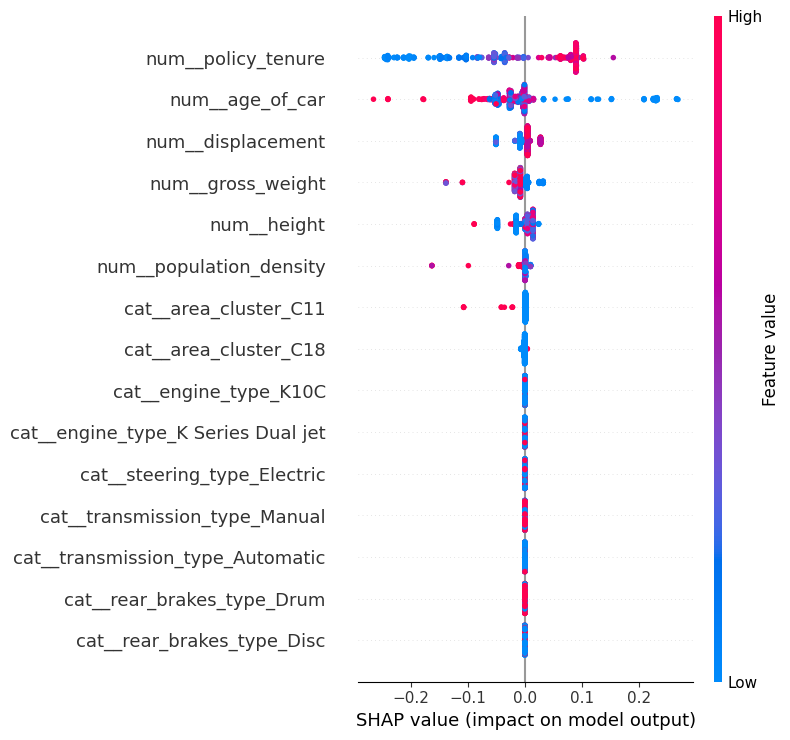

,feature,mean_abs_shap,mean_signed_shap,direction
0,num__policy_tenure,0.095270,-0.016866,Negative contribution on explainer output scale
1,num__age_of_car,0.041173,-0.006894,Negative contribution on explainer output scale
10,num__displacement,0.013653,-0.002904,Negative contribution on explainer output scale
13,num__gross_weight,0.013289,-0.007991,Negative contribution on explainer output scale
12,num__height,0.013257,-0.001450,Negative contribution on explainer output scale
3,num__population_density,0.002863,-0.001231,Negative contribution on explainer output scale
24,cat__area_cluster_C11,0.002402,-0.000052,Negative contribution on explainer output scale
31,cat__area_cluster_C18,0.000494,-0.000459,Negative contribution on explainer output scale
6,num__is_adjustable_steering,0.000000,0.000000,Negative contribution on explainer output scale
2,num__age_of_policyholder,0.000000,0.000000,Negative contribution on explainer output scale


In [68]:
if isinstance(shap_values, list):
  positive_shap = shap_values[1] if len(shap_values) > 1 else shap_values[0]
else:positive_shap = np.asarray(shap_values)
if positive_shap.ndim == 3:
            positive_shap = positive_shap[:, :, 1]
positive_shap = np.asarray(positive_shap)
if positive_shap.ndim == 1:
        positive_shap = positive_shap.reshape(-1, 1)
shap.summary_plot(positive_shap, explain_sample, max_display=15, show=False)
plt.tight_layout()
plt.savefig(OUT_DIR / "shap_summary.png", dpi=160, bbox_inches="tight")
plt.show()
shap_summary = pd.DataFrame({
        "feature": explain_sample.columns,
        "mean_abs_shap": np.abs(positive_shap).mean(axis=0),
        "mean_signed_shap": positive_shap.mean(axis=0)
    })
shap_summary["direction"] = np.where(
        shap_summary["mean_signed_shap"] > 0,
        "Positive contribution on explainer output scale",
        "Negative contribution on explainer output scale"
    )
shap_summary = shap_summary.sort_values("mean_abs_shap", ascending=False)
shap_summary.to_csv(OUT_DIR / "shap_feature_summary.csv", index=False)
display(shap_summary.head(20))

## 11. Risk bands, predictions and monotonicity check
Risk bands use the 40th, 75th and 90th percentiles of held-out predicted probabilities. Tied cut points may produce empty bands; this is reported rather than artificially adjusting thresholds.

In [69]:
def assign_risk_levels(probabilities):
    q40, q75, q90 = np.quantile(probabilities, [0.40, 0.75, 0.90])
    levels = np.select(
        [probabilities <= q40, probabilities <= q75, probabilities <= q90],
        ["Low", "Medium", "High"],
        default="Very High"
    )
    return levels, {"q40": float(q40), "q75": float(q75), "q90": float(q90)}

risk_levels, risk_cut_points = assign_risk_levels(chosen_probability)
prediction_output = pd.DataFrame({
    "policy_id": policy_ids.loc[X_test.index].values,
    "actual_outcome": y_test.values,
    "predicted_class": chosen_prediction,
    "claim_probability": chosen_probability,
    "risk_level": risk_levels
})
prediction_output.to_csv(OUT_DIR / "prediction_output.csv", index=False)
print("Risk cut points:", risk_cut_points)
display(prediction_output.head())

Risk cut points: {'q40': 0.4757586666204691, 'q75': 0.6025659049892819, 'q90': 0.6025659049892819}


,policy_id,actual_outcome,predicted_class,claim_probability,risk_level
0,ID38216,0,1,0.602566,Medium
1,ID03598,0,0,0.224222,Low
2,ID32005,0,0,0.337325,Low
3,ID20541,0,1,0.602566,Medium
4,ID55339,0,0,0.224222,Low


In [70]:
risk_order = ["Low", "Medium", "High", "Very High"]
risk_summary = prediction_output.groupby("risk_level", observed=False).agg(
    policies=("actual_outcome", "size"),
    actual_claim_rate=("actual_outcome", "mean"),
    mean_probability=("claim_probability", "mean")
).reindex(risk_order)
display(risk_summary)
rates = risk_summary["actual_claim_rate"].dropna().tolist()
monotonic = all(rates[i] <= rates[i + 1] for i in range(len(rates) - 1))
print("Actual claim rate increases monotonically across populated risk bands:", monotonic)
if not monotonic:
    print("The monotonicity check failed. Report this result honestly; do not alter thresholds or outcomes.")
risk_summary.to_csv(OUT_DIR / "risk_band_summary.csv")

,policies,actual_claim_rate,mean_probability
risk_level,,,
Low,5645.0,0.040921,0.338651
Medium,5313.0,0.076228,0.569499
High,NaN,NaN,NaN
Very High,761.0,0.149803,0.687295


Actual claim rate increases monotonically across populated risk bands: True


### Interpretation: empty "High" band and monotonicity

The 75th and 90th percentile cut points are identical (q75 = q90 = 0.6026). The tuned decision tree (max_depth = 4) produces a limited number of distinct probability scores, and many held-out policies share the same score. No policy has a score strictly between q75 and q90, so the **High band is empty (0 policies)**. Its claim rate is undefined, not zero.

On the 11,719 held-out test policies, the Low band holds 5,645 policies (48.2%) with an observed claim rate of 4.09%. The Medium band holds 5,313 policies (45.3%) with a claim rate of 7.62%. The High band holds 0 policies. The Very High band holds 761 policies (6.5%) with a claim rate of 14.98%.

Observed claim rates increase monotonically across the **three populated bands** (Low < Medium < Very High). Monotonicity across all four bands cannot be claimed. The Very High band's claim rate is about 2.3 times the overall rate of 6.4%.

The cut points were not adjusted to fill the High band, because that would be tuning thresholds to improve the appearance of the result. The scores are model risk scores, not calibrated probabilities: the mean score is about 0.47 against an observed claim rate of about 6.4% (class_weight="balanced" inflates them). Calibration and a model with a more continuous score are future improvements.

## 12. Notebook 2 completion checklist
The output directory should contain model comparison, coefficients, model artifact, metadata, prediction output and—when dependencies are installed—MLflow logs, Evidently HTML and SHAP outputs. Review all warnings and actual results before interpreting the model.